Размер обучающей выборки: (60000, 784)
Размер тестовой выборки:   (10000, 784)
Форма одного изображения:  (28, 28)
Всего классов:         [0 1 2 3 4 5 6 7 8 9]


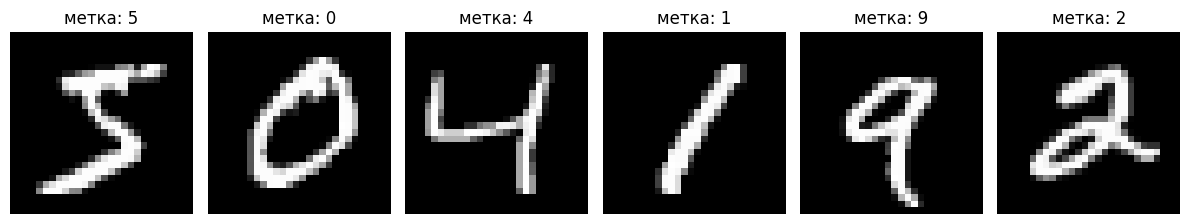

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')

X_all = mnist.data.astype(np.float32)/255.0
Y_all = mnist.target.astype(np.int64)
X_train, Y_train = X_all[:60000], Y_all[:60000]
X_test,  Y_test  = X_all[60000:], Y_all[60000:]

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:  ", X_test.shape)
print("Форма одного изображения: ", (28, 28))
print("Всего классов:        ", np.unique(Y_train))

fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"метка: {Y_train[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

In [2]:
def ReLu(x):
    return(np.maximum(0, x))

def deriv_ReLu(x):
    res = np.zeros_like(x)
    res[x > 0] = 1.0
    return (res)

def softmax(x): # численно устойчивая реализация, это помогает избежать переполнения 
    x_shift = x - np.max(x, axis=1, keepdims=True) # keepdims=True не меняет размерность
    e_x = np.exp(x_shift)
    return (e_x/np.sum(e_x, axis=1, keepdims=True))

def make_one_hot(y, num_classes):
    return np.eye(num_classes, dtype=np.float32)[y]

def init_parameters(n_input, n_hidden, n_output, seed):
    rand = np.random.default_rng(seed)
    std_W1 = np.sqrt(2.0 / n_input) # стандартное отклонение w1
    std_W2 = np.sqrt(2.0 / n_hidden)
    W1 = rand.normal(0.0, std_W1, size=(n_input, n_hidden)).astype(np.float32)
    b1 = np.zeros(n_hidden, dtype=np.float32)
    W2 = rand.normal(0.0, std_W2, size=(n_hidden, n_output)).astype(np.float32)
    b2 = np.zeros(n_output, dtype=np.float32) # приведение к float32 для ускорения работы и уменьшения затрат памяти
    return W1, b1, W2, b2

In [3]:
def forward(X, W1, b1, W2, b2):
    f = np.matmul(X, W1) + b1       # matmul - матричное умножение
    v = ReLu(f)
    g = np.matmul(v, W2) + b2
    u = softmax(g)
    return f, v, g, u

def backward(X, y_onehot, f, v, u, W2):
    N = X.shape[0]  # размер батча
    dg = (u - y_onehot)/N
    dW2 = np.matmul(v.T, dg)
    db2 = np.sum(dg, axis=0)
    dv = np.matmul(dg, W2.T)
    df = dv * deriv_ReLu(f)
    dW1 = np.matmul(X.T, df)
    db1 = np.sum(df, axis=0)
    return dW1, db1, dW2, db2

In [4]:
def train(X_train, Y_train, X_test, Y_test,
          n_hidden, speed, batch_size, epochs, seed):

    n_input  = X_train.shape[1] #размерность входа
    n_output = 10
    W1, b1, W2, b2 = init_parameters(n_input, n_hidden, n_output, seed)

    y_train_onehot = make_one_hot(Y_train, n_output)
    y_test_onehot  = make_one_hot(Y_test,  n_output)

    rand = np.random.default_rng(seed) # делает последовательность при одинаковом зерне воспроизводимой
    N = X_train.shape[0]

    for epoch in range(0, epochs):
        t_start = time.time()
        idx = rand.permutation(N)
        x_mixed = X_train[idx]
        y_mixed = y_train_onehot[idx]

        correct_pred  = 0
        for i in range(0, N, batch_size): # проходимся по всем батчам. производная по одному батчу делится на чслор батчей, т.е как бы идет аппроксимация
            X_batch = x_mixed[i:i + batch_size] # cрез
            Y_batch = y_mixed[i:i + batch_size]
            f, v, g, u = forward(X_batch, W1, b1, W2, b2)
            
            predictions = np.argmax(u, axis=1)         # получаем номера предсказанных классов по принципу max вероятностей  axis=1 - ищем по столбцам (максимум внутри строки)
            correct_answer = np.argmax(Y_batch, axis=1)
            correct_pred = correct_pred + np.sum(predictions == correct_answer)
            dW1, db1, dW2, db2 = backward(X_batch, Y_batch, f, v, u, W2)
            W1 = W1 - speed*dW1
            b1 = b1 - speed*db1
            W2 = W2 - speed*dW2
            b2 = b2 - speed*db2

        accuracy = correct_pred/N
        train_loss = 1 - accuracy
        t_end = time.time()
        dt =  t_end - t_start
        print(f"эпоха {(epoch +1):2d}/{epochs} | ошибка на тренировочной выборке={train_loss:.5f} | время={dt:.3f} с")

    return W1, b1, W2, b2

In [5]:
W1, b1, W2, b2 = train(X_train, Y_train, X_test, Y_test, n_hidden=300, speed=0.1, batch_size=32, epochs=20, seed=9)
correct_pred = 0
for i in range(0, X_test.shape[0], 1024): # экономим память
    _, _, _, u = forward(X_test[i:i + 1024], W1, b1, W2, b2)
    predictions = np.argmax(u, axis=1)
    correct_answer = Y_test[i:i + 1024]
    correct_pred = correct_pred + np.sum(predictions == correct_answer)
final_test_acc = correct_pred / X_test.shape[0]
print(f"\nточность на тестовой выборке: {final_test_acc*100:.2f}%")

эпоха  1/20 | ошибка на тренировочной выборке=0.08037 | время=4.267 с
эпоха  2/20 | ошибка на тренировочной выборке=0.03798 | время=4.073 с
эпоха  3/20 | ошибка на тренировочной выборке=0.02687 | время=4.107 с
эпоха  4/20 | ошибка на тренировочной выборке=0.02090 | время=4.027 с
эпоха  5/20 | ошибка на тренировочной выборке=0.01618 | время=4.432 с
эпоха  6/20 | ошибка на тренировочной выборке=0.01328 | время=4.028 с
эпоха  7/20 | ошибка на тренировочной выборке=0.01083 | время=3.957 с
эпоха  8/20 | ошибка на тренировочной выборке=0.00853 | время=3.949 с
эпоха  9/20 | ошибка на тренировочной выборке=0.00708 | время=3.954 с
эпоха 10/20 | ошибка на тренировочной выборке=0.00565 | время=3.933 с
эпоха 11/20 | ошибка на тренировочной выборке=0.00412 | время=3.893 с
эпоха 12/20 | ошибка на тренировочной выборке=0.00322 | время=3.953 с
эпоха 13/20 | ошибка на тренировочной выборке=0.00248 | время=3.812 с
эпоха 14/20 | ошибка на тренировочной выборке=0.00188 | время=3.848 с
эпоха 15/20 | ошибка